## Question:
### Across 1,000 simulated turns, what are the mean number of times a player lands on Boardwalk and the standard deviation of those occurrences?

## Description of the simulation:
### The variable we will be simulating is how many times a player lands on boardwalk (the variable would be boardwalk). 
### This will be done in 1000 simulated trials and possible outcomes are any amount of times it lands on boardwalk (it could either land on boardwalk 100 times or 5 times).

In [37]:
import pandas as pd
import random
import seaborn as sns
import matplotlib.pyplot as plt


# Game parameters
BOARD_SIZE = 40
BOARDWALK_INDEX = 39  # Boardwalk is space 39 (0-indexed, where GO = 0)
NUM_SIMULATIONS = 1000
TURNS_PER_SIMULATION = 100

In [38]:
# List to store the results of each simulation
boardwalk_counts = []

In [39]:
# Run 1,000 game simulations
for sim in range(NUM_SIMULATIONS):
    current_position = 0
    landings = 0

    # Simulate turns in a single game
    for turn in range(TURNS_PER_SIMULATION):
        # Roll two 6-sided dice
        die1 = random.randint(1, 6)
        die2 = random.randint(1, 6)
        total_roll = die1 + die2

        # Move forward on the board (wrap around using modulo)
        current_position = (current_position + total_roll) % BOARD_SIZE

        # Check if landed on Boardwalk
        if current_position == BOARDWALK_INDEX:
            landings = landings + 1

    # Add the result of this simulation to our list
    boardwalk_counts.append(landings)

In [40]:
# Calculate Mean
total_landings = sum(boardwalk_counts)
mean_landings = total_landings / NUM_SIMULATIONS

In [41]:
# Calculate Standard Deviation
sum_squared_diffs = 0
for count in boardwalk_counts:
    diff = count - mean_landings
    sum_squared_diffs = sum_squared_diffs + (diff ** 2)

In [42]:
# Sample standard deviation formula: sqrt( sum( (x - mean)^2 ) / (N - 1) )
std_dev = (sum_squared_diffs / (NUM_SIMULATIONS - 1)) ** 0.5

In [43]:
# Display Results
print("Mean landings on Boardwalk:", mean_landings)
print("Standard deviation:", std_dev)

Mean landings on Boardwalk: 2.494
Standard deviation: 1.4751746134407833


Text(0, 0.5, 'Probability')

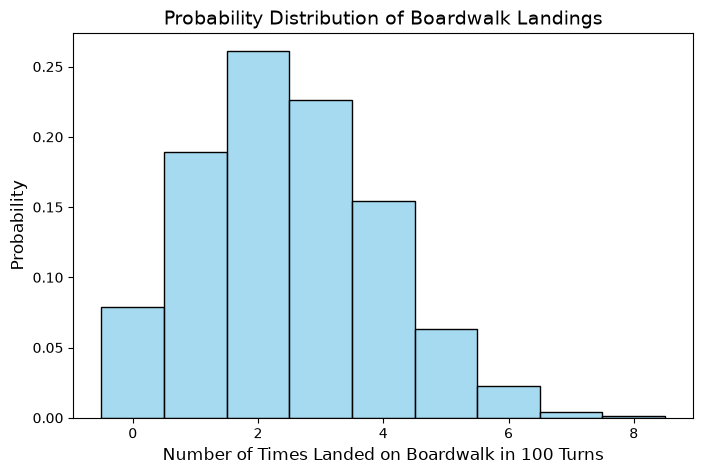

In [44]:
plt.figure(figsize = (8,5))

ax = sns.histplot(
    boardwalk_counts,
    discrete=True,
    stat="probability",
    color="skyblue",
    edgecolor="black",
)
# Add title and axis labels
plt.title(
    "Probability Distribution of Boardwalk Landings",
    fontsize=14,
)
plt.xlabel("Number of Times Landed on Boardwalk in 100 Turns", fontsize=12)
plt.ylabel("Probability", fontsize=12)

In [45]:
df = pd.DataFrame({'boardwalk_counts': boardwalk_counts})

metrics = pd.Series({
    'Mean Landings': df['boardwalk_counts'].mean(),
    'Standard Deviation': df['boardwalk_counts'].std()
})

(0.0, 3.2422000000000004)

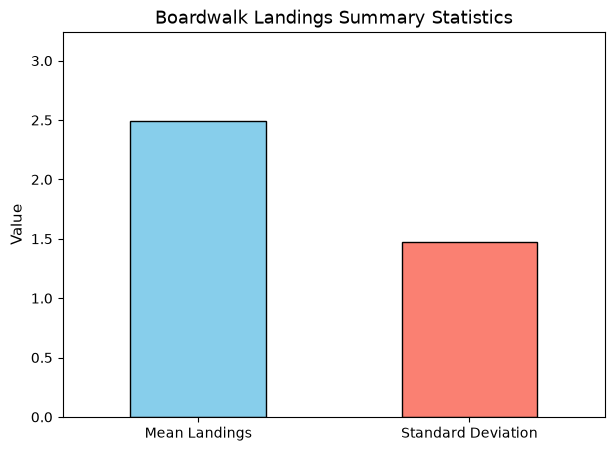

In [46]:
# 2. Plot as a pandas bar chart
ax = metrics.plot(kind='bar', color=['skyblue', 'salmon'], edgecolor='black', width=0.5, figsize=(7, 5))

plt.title('Boardwalk Landings Summary Statistics', fontsize=13)
plt.ylabel('Value', fontsize=11)
plt.xticks(rotation=0)
plt.ylim(0, max(metrics) * 1.3)

In [47]:
# Annotate exact bar heights
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(f'{height:.2f}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4), textcoords="offset points",
                ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

## My Conclusion:
### Based on this simulation, we can see that the mean landings on boardwalk is 2.494. We can see that the standard deviation is 1.48 (rounded to the nearest hundredth).
### This graph shows us the mean landings and standard deviations of the data. According to the graph we can see that the mean landings is almost at 2.5 and the standard deviation is almost 1.5 